<a href="https://colab.research.google.com/github/josmimaria/Machine-Learning/blob/development/3_0_SMOTE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## SMOTE(Synthetic Minority Oversampling Technique)
SMOTE (Synthetic Minority Over-sampling Technique) is a technique used in machine learning to address imbalanced datasets where the minority class has significantly fewer instances than the majority class. SMOTE involves generating synthetic instances of the minority class by interpolating between existing instances.

In [15]:
from sklearn.datasets import make_classification

In [16]:
X,y=make_classification(n_samples=1000,n_redundant=0,n_features=2,n_clusters_per_class=1,
                   weights=[0.90],random_state=12)

In [17]:
X.shape

(1000, 2)

In [18]:
len(y[y==1])

100

In [19]:
import pandas as pd
df1=pd.DataFrame(X,columns=['f1','f2'])
df2=pd.DataFrame(y,columns=['target'])
final_df=pd.concat([df1,df2],axis=1)
final_df.head()

,f1,f2,target
0,-0.762898,-0.706808,0
1,-1.075436,-1.051162,0
2,-0.610115,-0.909802,0
3,-2.023284,-0.428945,1
4,-0.812921,-1.316206,0


In [20]:
final_df['target'].value_counts()

,count
target,
0,900
1,100


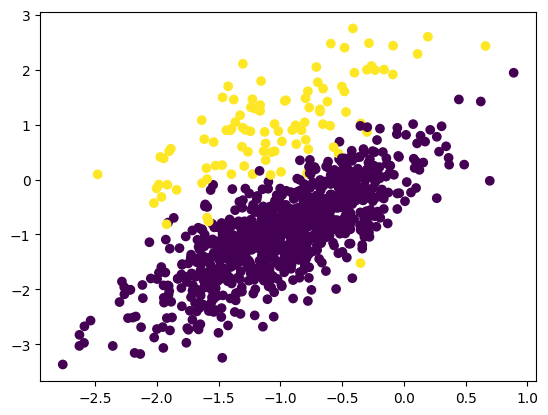

In [21]:
import matplotlib.pyplot as plt
plt.scatter(final_df['f1'],final_df['f2'],c=final_df['target'])

In [ ]:
!pip install imblearn

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
## transform the dataset
oversample=SMOTE()
X,y=oversample.fit_resample(final_df[['f1','f2']],final_df['target'])

In [ ]:
X.shape

(1800, 2)

In [ ]:
y.shape

(1800,)

In [ ]:
len(y[y==0])

900

In [ ]:
len(y[y==1])

900

In [ ]:
df1=pd.DataFrame(X,columns=['f1','f2'])
df2=pd.DataFrame(y,columns=['target'])
oversample_df=pd.concat([df1,df2],axis=1)

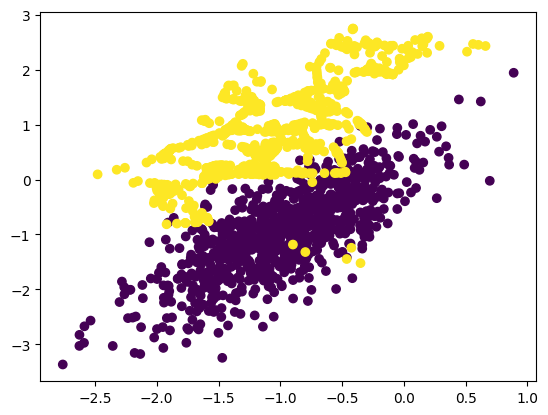

In [ ]:
plt.scatter(oversample_df['f1'],oversample_df['f2'],c=oversample_df['target'])

## Example 2

In [2]:
pip install imbalanced-learn

In [6]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
import pandas as pd

In [24]:
import numpy as np
np.random.seed(42)

# Create 900 majority-class samples
feature1_0 = np.random.normal(5, 2, 900)
feature2_0 = np.random.normal(5, 2, 900)

# Create 100 minority-class samples
feature1_1 = np.random.normal(10, 1.5, 100)
feature2_1 = np.random.normal(10, 1.5, 100)

# Create DataFrame
df = pd.DataFrame({
    'feature1': np.concatenate([feature1_0, feature1_1]),
    'feature2': np.concatenate([feature2_0, feature2_1]),
    'target': [0] * 900 + [1] * 100
})

print(df.head())

   feature1  feature2  target
0  5.993428  5.737347       0
1  4.723471  4.213322       0
2  6.295377  5.057490       0
3  8.046060  7.556904       0
4  4.531693  5.382198       0


In [25]:
x = df[['feature1','feature2']]
y = df['target']

In [26]:
# 3. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


In [27]:
df['target'].value_counts()

,count
target,
0,900
1,100


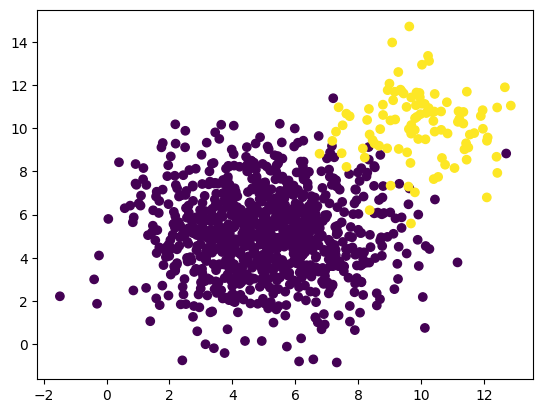

In [28]:
import matplotlib.pyplot as plt
plt.scatter(df['feature1'],df['feature2'],c=df['target'])

In [30]:
from imblearn.over_sampling import SMOTE
# 4. Apply SMOTE to training data only
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train, y_train
)


In [31]:
df['target'].value_counts()

,count
target,
0,900
1,100


In [32]:
X_train_resampled.shape

(1440, 2)

In [33]:
y_train_resampled.shape

(1440,)

In [36]:
len(y_train_resampled[y_train_resampled==0])

720

In [37]:
len(y_train_resampled[y_train_resampled==1])

720

In [38]:
df1=pd.DataFrame(X_train_resampled,columns=['feature1','feature2'])
df2=pd.DataFrame(y_train_resampled,columns=['target'])
oversample_df=pd.concat([df1,df2],axis=1)

In [40]:
oversample_df['target'].value_counts()


,count
target,
0,720
1,720


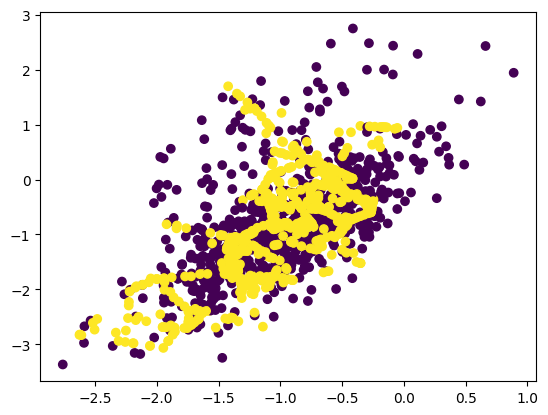

In [39]:
plt.scatter(oversample_df['feature1'],oversample_df['feature2'],c=oversample_df['target'])